# Gaussian-process master curves and fractional model fits

This notebook redoes the time-temperature superposition from `trios_analysis.ipynb` with two outside packages:

* **`mastercurves`** (Lennon, McKinley & Swan, *J. Rheol.* 2023, [arXiv:2204.09521](https://arxiv.org/abs/2204.09521)).
  It fits a Gaussian process (GP) to each isotherm in log-log space, then picks the shift factor that maximizes the likelihood
  of one isotherm's data under the GP of its neighbor. The curvature of that likelihood gives an uncertainty on each $a_T$.
  Trios gives only a single number.
* **`pyRheo`** (Miranda-Valdez et al., [github.com/mirandi1/pyRheo](https://github.com/mirandi1/pyRheo)). Its `SAOSModel(model="auto")`
  runs a pretrained neural-network classifier on PCA features of $G'(\omega)$ and $G''(\omega)$ to choose a (fractional) viscoelastic model,
  then fits it.

Questions:
1. Does the choice of shifted quantity ($G'$, $G''$, $|G^*|$, $\tan\delta$) change $a_T$, and by more than the GP uncertainty?
2. Why was HT 2181 hard to shift in Trios?
3. What does a different HT activation energy do to the line-speed optimum at 330 °C, which is an extrapolation?
4. Do fractional models give zero-shear viscosities that agree with the Cross fits?

In [16]:
import sys, io, contextlib, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import LogLocator, NullFormatter

from mastercurves import MasterCurve
from mastercurves.transforms import Multiply
from pyRheo import SAOSModel

warnings.filterwarnings("ignore")          # sklearn GP convergence chatter
pd.set_option("display.float_format", lambda v: f"{v:.4g}")
pd.set_option("display.width", 200)

R = 8.314
K0 = 273.15
BASE = Path(".")
FIG_DIR = BASE / "figures"
FIG_DIR.mkdir(exist_ok=True)


def save_fig(fig, name, **kwargs):
    for ext in ("png", "pdf"):
        fig.savefig(FIG_DIR / f"{name}.{ext}", dpi=600, bbox_inches="tight", **kwargs)


def pure_decades(ax):
    for axis in (ax.xaxis, ax.yaxis):
        axis.set_major_locator(LogLocator(base=10.0, subs=(1.0,)))
        axis.set_minor_formatter(NullFormatter())

## Load the sweeps

Same files, reader and Trios shift tables as `trios_analysis.ipynb`. Each sweep also gets the same degradation rule used there:
sweeps run from high to low frequency, and a low-frequency point whose $|\eta^*|$ falls more than 1% below the running maximum is dropped.

In [17]:
POLYMERS = {
    "FEP": {
        "ref": 330,
        "shift_file": "FEP/FEP 9835 2007390112 mfr 24.8 330°C.txt",
        "sweeps": {
            330: "FEP/FEP 9835 2007390112 mfr 24.8 330°C.txt",
            350: "FEP/TE9835 Lot 2007390112 at 350°C.txt",
            370: "FEP/TE9835 Lot 2007390112 at 370°C.txt",
        },
    },
    "PFA 440HPAX": {
        "ref": 330,
        "shift_file": "PFA/PFA 440HPAX Lot 2103470009 at 330°C.txt",
        "sweeps": {
            330: "PFA/PFA 440HPAX Lot 2103470009 at 330°C.txt",
            350: "PFA/PFA 440  Lot 2103470009 mfr 15.5 at 350°C.txt",
            370: "PFA/PFA 440  Lot 2103470009 mfr 15.5 at 370°C.txt",
        },
    },
    "HT 2181": {
        "ref": 300,
        "shift_file": "HT/HT 2181 1212PASK 22 MFR 6,4 315°C.txt",
        "sweeps": {
            285: "HT/HT 2181 1212PASK 22 MFR 6,4 285°C.txt",
            300: "HT/HT 2181 1212PASK 22 MFR 6,4 300°C.txt",
            315: "HT/HT 2181 1212PASK 22 MFR 6,4 315°C.txt",
        },
    },
}


def _num(x):
    try:
        return float(x)
    except ValueError:
        return np.nan


def read_steps(path):
    # Split a TRIOS export into its steps, keeping the variable names and data rows.
    steps, cur = [], None
    for line in Path(path).read_text(encoding="utf-8", errors="replace").splitlines():
        if line.startswith("Step name\t"):
            cur = {"name": line.split("\t", 1)[1], "vars": None, "rows": []}
            steps.append(cur)
        elif cur is None:
            continue
        elif line.startswith("Variables\t"):
            cur["vars"] = line.split("\t")[1:]
        elif line.startswith("Data point\t"):
            cur["rows"].append([_num(x) for x in line.split("\t")[1:]])
    return steps


def column(step, name):
    idx = step["vars"].index(name)
    return np.array([r[idx] for r in step["rows"]], float)


def load_shift_table(path):
    step = next(s for s in read_steps(path) if "shift" in s["name"].lower())
    T, aT = column(step, "Temperature"), column(step, "aT (x variable)")
    _, idx = np.unique(np.round(T), return_index=True)
    return T[idx], aT[idx]


def degraded_points(w, eta, tol=0.01):
    order = np.argsort(w)[::-1]
    running_max = np.maximum.accumulate(eta[order])
    bad = np.zeros_like(w, bool)
    bad[order] = eta[order] < (1 - tol) * running_max
    return bad


def load_sweep(path):
    # Returns a dict of arrays sorted by frequency, with degraded low-frequency points removed.
    step = next(s for s in read_steps(path) if s["name"].startswith("Frequency"))
    w = column(step, "Angular frequency")
    Gp = column(step, "Storage modulus") * 1e6        # MPa -> Pa
    Gpp = column(step, "Loss modulus") * 1e6
    keep = ~degraded_points(w, column(step, "Complex viscosity"))
    o = np.argsort(w[keep])
    w, Gp, Gpp = w[keep][o], Gp[keep][o], Gpp[keep][o]
    return {"w": w, "G'": Gp, "G''": Gpp, "|G*|": np.hypot(Gp, Gpp), "tan δ": Gpp / Gp}


DATA = {}
for name, cfg in POLYMERS.items():
    Tt, aTt = load_shift_table(cfg["shift_file"])
    temps = sorted(cfg["sweeps"])
    DATA[name] = {
        "ref": cfg["ref"],
        "temps": temps,
        "sweeps": {T: load_sweep(cfg["sweeps"][T]) for T in temps},
        "aT_trios": {T: aTt[np.argmin(np.abs(Tt - T))] for T in temps},
    }
    print(name, {T: len(DATA[name]["sweeps"][T]["w"]) for T in temps}, "points per sweep")

FEP {330: 23, 350: 21, 370: 21} points per sweep
PFA 440HPAX {330: 22, 350: 24, 370: 22} points per sweep
HT 2181 {285: 23, 300: 22, 315: 20} points per sweep


## GP superposition

`gp_shift` wraps `MasterCurve` for one polymer and one quantity. States are passed in order of increasing temperature,
so each pairwise shift is the next-hotter isotherm onto the previous one (ratio between 0.05 and 1).
All superposition in this notebook is horizontal only: no vertical shift is applied ($b_T = 1$).

Two notes on the package:
* `MasterCurve.change_ref` mishandles the uncertainty of states *below* the new reference.
  So the reference is moved by hand here. The package reports each pairwise shift's uncertainty from the Hessian of the negative
  log-posterior; those are added in quadrature along the chain from the reference state, in $\ln a$.
* The GP noise floor is the package default (`fixed_noise=0.04`, about 4% in the modulus).

In [18]:
QUANTITIES = ["G'", "G''", "|G*|", "tan δ"]


def gp_shift(name, quantity, h_bounds=(0.05, 1.0)):
    d = DATA[name]
    temps = d["temps"]
    mc = MasterCurve()
    mc.add_data([np.log(d["sweeps"][T]["w"]) for T in temps],
                [np.log(d["sweeps"][T][quantity]) for T in temps],
                [float(T) for T in temps])
    mc.add_htransform(Multiply(bounds=h_bounds, scale="log"))
    mc.superpose()

    def rebase(params, sigmas):
        p = np.asarray(params, float)
        rel_cum = np.asarray(sigmas, float) / p                 # cumulative relative s.d. from state 0
        var_pair = np.diff(rel_cum ** 2, prepend=0.0)           # pairwise variances in ln p
        r = temps.index(d["ref"])
        ln_p = np.log(p / p[r])
        sig = np.array([np.sqrt(var_pair[min(i, r) + 1:max(i, r) + 1].sum()) for i in range(len(temps))])
        return np.exp(ln_p), sig

    a, sig_ln_a = rebase(mc.hparams[0], mc.huncertainties[0])
    return {"mc": mc, "a": a, "sig_ln_a": sig_ln_a}


SHIFTS = {name: {q: gp_shift(name, q) for q in QUANTITIES} for name in DATA}

rows = []
for name, d in DATA.items():
    for T in d["temps"]:
        if T == d["ref"]:
            continue
        i = d["temps"].index(T)
        row = {"polymer": name, "T [°C]": T, "Trios": d["aT_trios"][T]}
        for q in QUANTITIES:
            s = SHIFTS[name][q]
            row[q] = f"{s['a'][i]:.3f} ± {2 * s['sig_ln_a'][i] * s['a'][i]:.3f}"
        rows.append(row)
print("a_T relative to T_ref (± is 2σ from the GP posterior). Horizontal shift only.")
pd.DataFrame(rows).set_index(["polymer", "T [°C]"])

a_T relative to T_ref (± is 2σ from the GP posterior). Horizontal shift only.


Trios             G'            G''           |G*|          tan δ
polymer     T [°C]                                                                   
FEP         350    0.7415  0.779 ± 0.009  0.744 ± 0.012  0.739 ± 0.011  0.827 ± 0.028
            370    0.5281  0.579 ± 0.009  0.530 ± 0.012  0.530 ± 0.011  0.635 ± 0.031
PFA 440HPAX 350    0.7352  0.746 ± 0.007  0.736 ± 0.012  0.735 ± 0.011  0.760 ± 0.019
            370    0.5792  0.598 ± 0.008  0.581 ± 0.013  0.579 ± 0.012  0.634 ± 0.022
HT 2181     285      1.54  1.696 ± 0.024  1.534 ± 0.032  1.556 ± 0.030  2.029 ± 0.087
            315    0.5548  0.524 ± 0.007  0.583 ± 0.012  0.574 ± 0.011  0.436 ± 0.018

## Activation energies

Weighted Arrhenius fit of $\ln a_T$ against $1/T$, through $(1/T_\text{ref}, 0)$ by construction of $a_T$.
The GP gives the weights. With three temperatures and the reference fixed at zero there are two data points per fit,
so the quoted error on $E_a$ is propagated from the $a_T$ uncertainties, not estimated from scatter.

In [19]:
def arrhenius(name, a, sig_ln_a):
    d = DATA[name]
    x = 1 / (np.array(d["temps"]) + K0) - 1 / (d["ref"] + K0)
    y = np.log(a)
    keep = x != 0
    w = 1 / sig_ln_a[keep] ** 2
    slope = np.sum(w * x[keep] * y[keep]) / np.sum(w * x[keep] ** 2)   # weighted LSQ through origin
    sig_slope = 1 / np.sqrt(np.sum(w * x[keep] ** 2))
    return slope * R / 1e3, sig_slope * R / 1e3                       # kJ/mol


def arrhenius_unweighted(name, aT):
    d = DATA[name]
    x = 1 / (np.array(d["temps"]) + K0) - 1 / (d["ref"] + K0)
    y = np.log([aT[T] for T in d["temps"]])
    return np.sum(x * y) / np.sum(x * x) * R / 1e3


EA = {}
rows = []
for name in DATA:
    row = {"polymer": name, "Trios": arrhenius_unweighted(name, DATA[name]["aT_trios"])}
    EA[name] = {"Trios": (row["Trios"], np.nan)}
    for q in QUANTITIES:
        s = SHIFTS[name][q]
        Ea, sEa = arrhenius(name, s["a"], s["sig_ln_a"])
        EA[name][q] = (Ea, sEa)
        row[q] = f"{Ea:.1f} ± {2 * sEa:.1f}"
    rows.append(row)
print("E_a [kJ/mol], ± is 2σ")
pd.DataFrame(rows).set_index("polymer")

E_a [kJ/mol], ± is 2σ


,Trios,G',G'',|G*|,tan δ
polymer,,,,,
FEP,50.48,42.3 ± 1.0,49.4 ± 1.5,49.8 ± 1.4,34.1 ± 3.1
PFA 440HPAX,44.88,42.9 ± 0.9,45.2 ± 1.4,45.5 ± 1.4,38.9 ± 2.3
HT 2181,92.44,106.5 ± 1.8,87.6 ± 2.6,90.3 ± 2.5,139.8 ± 5.5


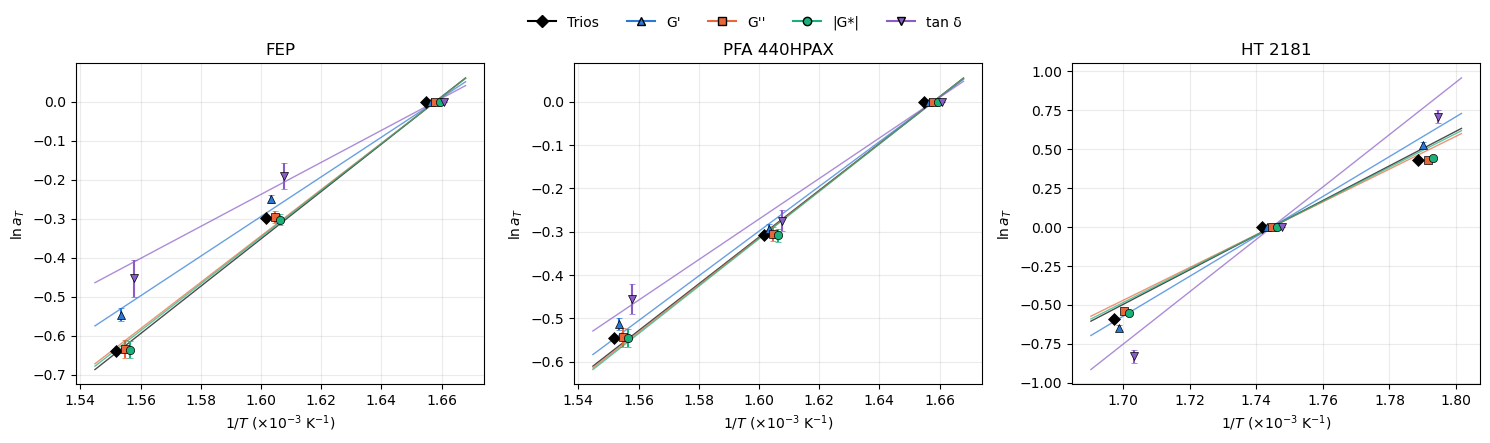

In [20]:
Q_STYLE = {"Trios": ("k", "D"), "G'": ("#2a78d6", "^"), "G''": ("#e8663a", "s"),
           "|G*|": ("#1baf7a", "o"), "tan δ": ("#8a5cc7", "v")}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, name in zip(axes, DATA):
    d = DATA[name]
    invT = 1e3 / (np.array(d["temps"]) + K0)
    xx = np.linspace(invT.min() - 0.01, invT.max() + 0.01, 50)
    for k, q in enumerate(["Trios"] + QUANTITIES):
        c, mk = Q_STYLE[q]
        dx = (k - 2) * 0.0015                                  # small offset so error bars don't overlap
        if q == "Trios":
            y, err = np.log([d["aT_trios"][T] for T in d["temps"]]), None
        else:
            y, err = np.log(SHIFTS[name][q]["a"]), 2 * SHIFTS[name][q]["sig_ln_a"]
        ax.errorbar(invT + dx, y, yerr=err, fmt=mk, color=c, mec="k", mew=0.5, ms=6, capsize=2, ls="none")
        Ea = EA[name][q][0] * 1e3
        ax.plot(xx, Ea / R * (xx / 1e3 - 1 / (d["ref"] + K0)), "-", color=c, lw=1, alpha=0.7)
    ax.set_title(name)
    ax.set_xlabel(r"$1/T$ ($\times 10^{-3}$ K$^{-1}$)")
    ax.set_ylabel(r"$\ln a_T$")
    ax.grid(alpha=0.25)
handles = [Line2D([], [], color=Q_STYLE[q][0], marker=Q_STYLE[q][1], mec="k", ls="-", label=q) for q in ["Trios"] + QUANTITIES]
fig.legend(handles=handles, loc="upper center", ncol=5, frameon=False, bbox_to_anchor=(0.5, 1.06))
fig.tight_layout()
save_fig(fig, "gp_arrhenius_by_quantity")
plt.show()

## Why HT 2181 is hard to shift

If $\log G$ against $\log\omega$ is close to a straight line, sliding one isotherm along it barely changes how well it overlaps
its neighbour, so the best horizontal shift is poorly defined. It is then set by small differences in curvature and by any small
vertical offset between isotherms (density change, sample loading, slight degradation), which a horizontal-only fit has to absorb
as a change in $a_T$.

The local slopes below show how close each polymer is to that case over the measured window.

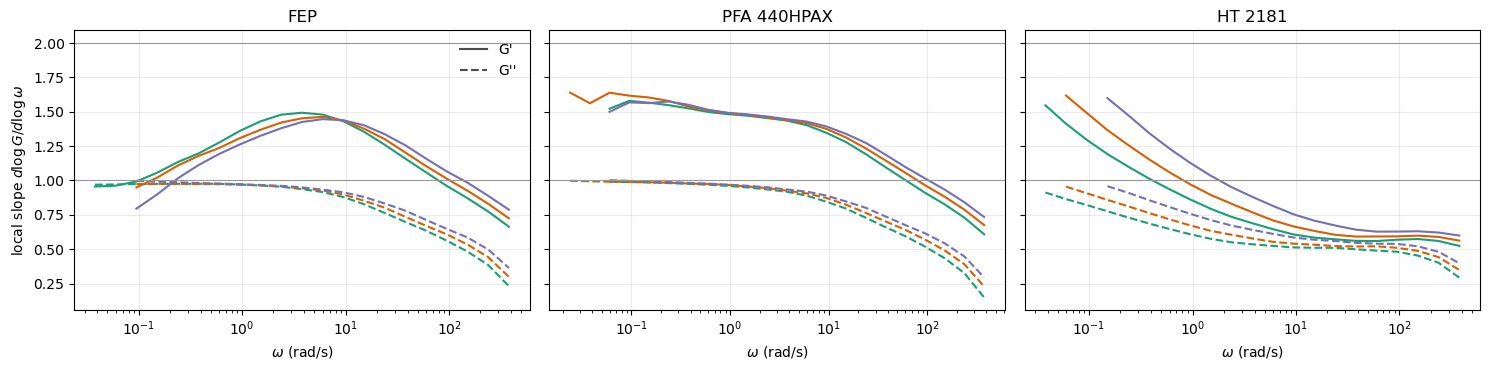

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, name in zip(axes, DATA):
    d = DATA[name]
    for T, c in zip(d["temps"], ["#1b9e77", "#d95f02", "#7570b3"]):
        sw = d["sweeps"][T]
        lw = np.log10(sw["w"])
        for q, ls in [("G'", "-"), ("G''", "--")]:
            ax.plot(sw["w"][1:-1], np.gradient(np.log10(sw[q]), lw)[1:-1], ls, color=c, lw=1.5)
    ax.set_xscale("log")
    ax.set_title(name)
    ax.set_xlabel(r"$\omega$ (rad/s)")
    ax.axhline(1, color="0.6", lw=0.8)
    ax.axhline(2, color="0.6", lw=0.8)
    ax.grid(alpha=0.25)
axes[0].set_ylabel(r"local slope $d\log G/d\log\omega$")
axes[0].legend(handles=[Line2D([], [], color="0.3", ls="-", label="G'"), Line2D([], [], color="0.3", ls="--", label="G''")],
               frameon=False, loc="upper right")
fig.tight_layout()
save_fig(fig, "gp_local_slopes")
plt.show()


## GP master curves

$|G^*|$ combines both moduli and is less noisy than $G'$ at low frequency, so it is used for the master curves and the `pyRheo` fits below.
Left: each isotherm and its GP (mean ± 2σ). Right: master curve built from the GP shift factors.

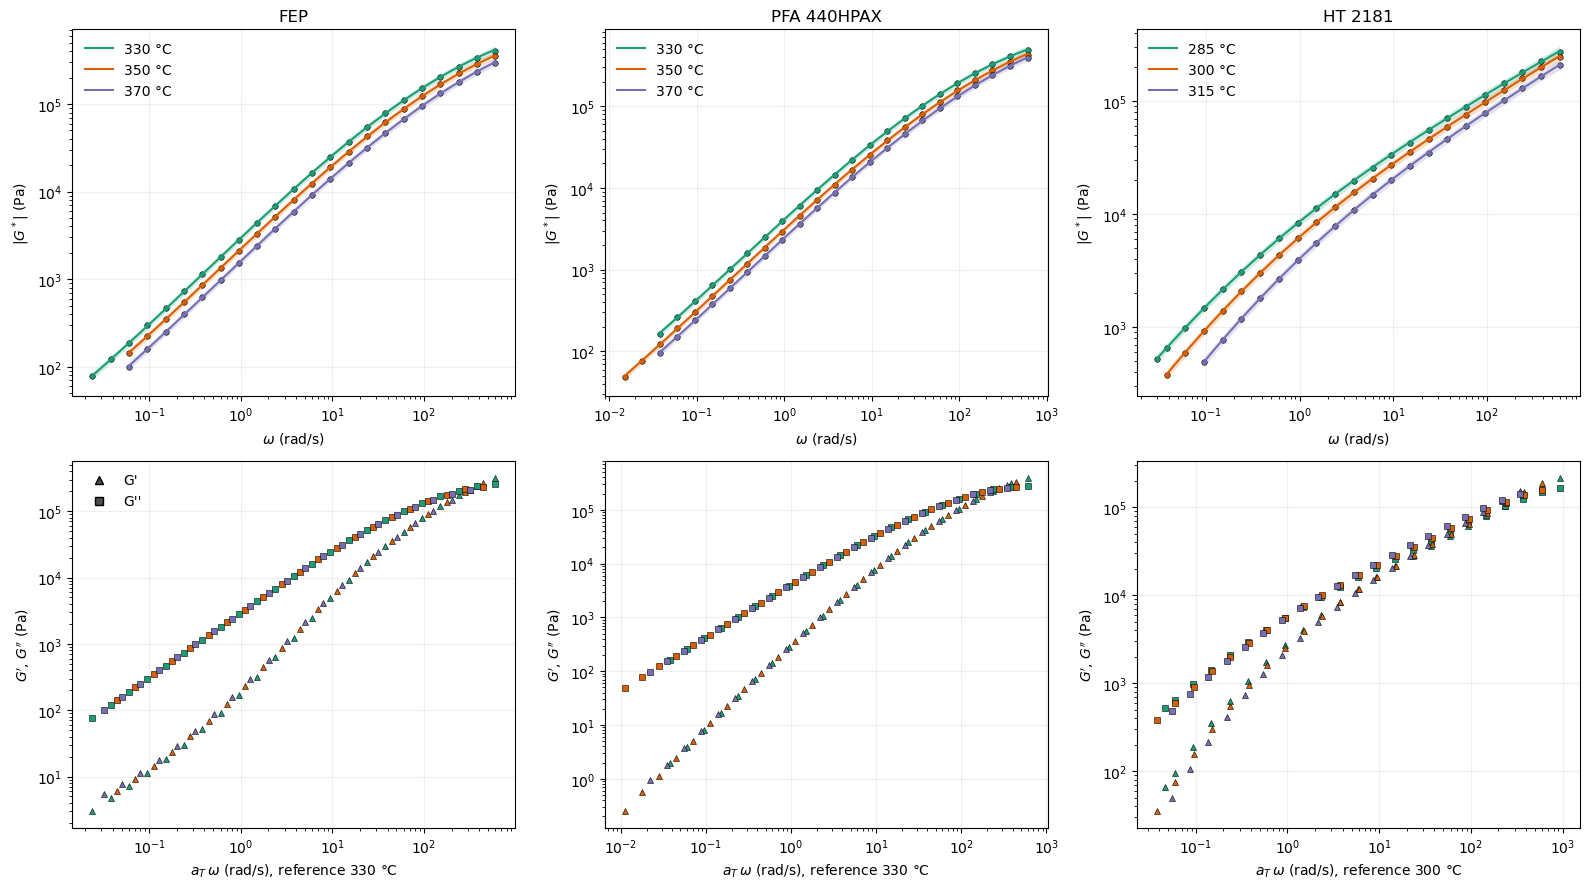

In [22]:
TEMP_COLORS = ["#1b9e77", "#d95f02", "#7570b3"]
MASTER = {}

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for col, name in enumerate(DATA):
    d = DATA[name]
    s = SHIFTS[name]["|G*|"]
    mc = s["mc"]
    ax_gp, ax_m = axes[0, col], axes[1, col]
    W, G1, G2 = [], [], []
    for i, (T, c) in enumerate(zip(d["temps"], TEMP_COLORS)):
        sw = d["sweeps"][T]
        xg = np.linspace(np.log(sw["w"].min()), np.log(sw["w"].max()), 200)
        mu, sd = mc.gps[i].predict(xg.reshape(-1, 1), return_std=True)
        ax_gp.plot(sw["w"], sw["|G*|"], "o", color=c, mec="k", mew=0.4, ms=4)
        ax_gp.plot(np.exp(xg), np.exp(mu), color=c, lw=1.5, label=f"{T} °C")
        ax_gp.fill_between(np.exp(xg), np.exp(mu - 2 * sd), np.exp(mu + 2 * sd), color=c, alpha=0.2, lw=0)

        x = sw["w"] * s["a"][i]
        ax_m.plot(x, sw["G'"], "^", color=c, mec="k", mew=0.4, ms=5)
        ax_m.plot(x, sw["G''"], "s", color=c, mec="k", mew=0.4, ms=5)
        W.append(x); G1.append(sw["G'"]); G2.append(sw["G''"])
    o = np.argsort(np.concatenate(W))
    MASTER[name] = {"w": np.concatenate(W)[o], "G'": np.concatenate(G1)[o], "G''": np.concatenate(G2)[o]}

    for ax in (ax_gp, ax_m):
        ax.set_xscale("log"); ax.set_yscale("log"); pure_decades(ax); ax.grid(alpha=0.2)
    ax_gp.set_title(name)
    ax_gp.set_xlabel(r"$\omega$ (rad/s)"); ax_gp.set_ylabel(r"$|G^*|$ (Pa)")
    ax_gp.legend(frameon=False, loc="upper left")
    ax_m.set_xlabel(rf"$a_T\,\omega$ (rad/s), reference {d['ref']} °C"); ax_m.set_ylabel(r"$G'$, $G''$ (Pa)")
axes[1, 0].legend(handles=[Line2D([], [], color="0.3", marker="^", ls="none", mec="k", label="G'"),
                           Line2D([], [], color="0.3", marker="s", ls="none", mec="k", label="G''")],
                  frameon=False, loc="upper left")
fig.tight_layout()
save_fig(fig, "gp_master_curves")
plt.show()

## Fractional viscoelastic models with `pyRheo`

`SAOSModel(model="auto")` interpolates $G'$ and $G''$ onto the frequency grid the classifier was trained on, smooths them, projects them onto
pretrained PCA components, and passes those to a small neural network (MLP) that picks one of six models.
The chosen model is then fit by minimizing the relative residual sum of squares over many random starts.

The candidates that matter here:
* **Fractional Maxwell** (FM): two spring-pots in series, $\mathbb{V}$ with order $\alpha$ and $\mathbb{G}$ with order $\beta$ (4 parameters).
* **Fractional Maxwell liquid** (FML): FM with $\alpha = 1$, so the first element is a dashpot of viscosity $\eta_s$ (3 parameters).
  FML is fit both from random starts and from the FM result, and the better of the two is kept. For FEP both land on the same, worse fit (see below).
  Its zero-shear viscosity is $\eta_s$, which can be compared directly with the Cross $\eta_0$.

Note: `pyRheo`'s package-level loss weights each residual by the data value, so the fit is in relative error. The `Cross` model in
`pyRheo.rotation_model` was also tried but its random-start fits were unstable on these data (its parameter `a` is unused in the model, so the
fit is degenerate), so the Cross values below come from `trios_analysis.ipynb`.

In [23]:
CROSS = pd.read_csv("cross_model_parameters.csv", index_col=0)
eta0_cross = {name: float(str(CROSS.loc[name, "η0 (Pa·s)"]).split("±")[0]) for name in DATA}


def quiet(fn, *args, **kwargs):
    buf = io.StringIO()
    with contextlib.redirect_stdout(buf):
        out = fn(*args, **kwargs)
    return out, buf.getvalue()


np.random.seed(0)
FITS, rows = {}, []
for name, m in MASTER.items():
    auto = SAOSModel(model="auto", initial_guesses="random", num_initial_guesses=64, minimization_algorithm="Powell")
    _, log = quiet(auto.fit, m["w"], m["G'"], m["G''"])
    picked = auto.model
    pa = auto.get_parameters()
    # FML from random starts, and FML seeded from the FM fit (FM with alpha -> 1 is FML); keep the lower cost
    fml_r = SAOSModel(model="FractionalMaxwellLiquid", initial_guesses="random", num_initial_guesses=64, minimization_algorithm="Powell")
    quiet(fml_r.fit, m["w"], m["G'"], m["G''"])
    fml_s = SAOSModel(model="FractionalMaxwellLiquid", initial_guesses="manual", minimization_algorithm="Powell")
    quiet(fml_s.fit, m["w"], m["G'"], m["G''"], initial_guesses=[pa["G"], pa["V"], pa["beta"]])
    fml = min((fml_r, fml_s), key=lambda f: f.cost_)
    FITS[name] = {"auto": auto, "FML": fml}
    pf = fml.get_parameters()
    n = 2 * len(m["w"])
    rows.append({
        "polymer": name,
        "classifier pick": picked,
        "FM α": pa.get("alpha", np.nan), "FM β": pa.get("beta", np.nan),
        "FM rms rel. err": np.sqrt(pa["Cost"] / n),
        "FML β": pf["beta"], "FML η_s [Pa s]": pf["eta_s"],
        "FML rms rel. err": np.sqrt(pf["Cost"] / n),
        "Cross η0 [Pa s]": eta0_cross[name],
    })
pd.DataFrame(rows).set_index("polymer")

,classifier pick,FM α,FM β,FM rms rel. err,FML β,FML η_s [Pa s],FML rms rel. err,Cross η0 [Pa s]
polymer,,,,,,,,
FEP,FractionalMaxwell,0.9788,0.294,0.05862,0.4764,3223,0.1991,3044
PFA 440HPAX,FractionalMaxwell,0.9993,0.3901,0.05157,0.401,4422,0.05457,4214
HT 2181,FractionalMaxwell,1,0.4684,0.09349,0.4685,1.128e+04,0.09348,1.278e+04


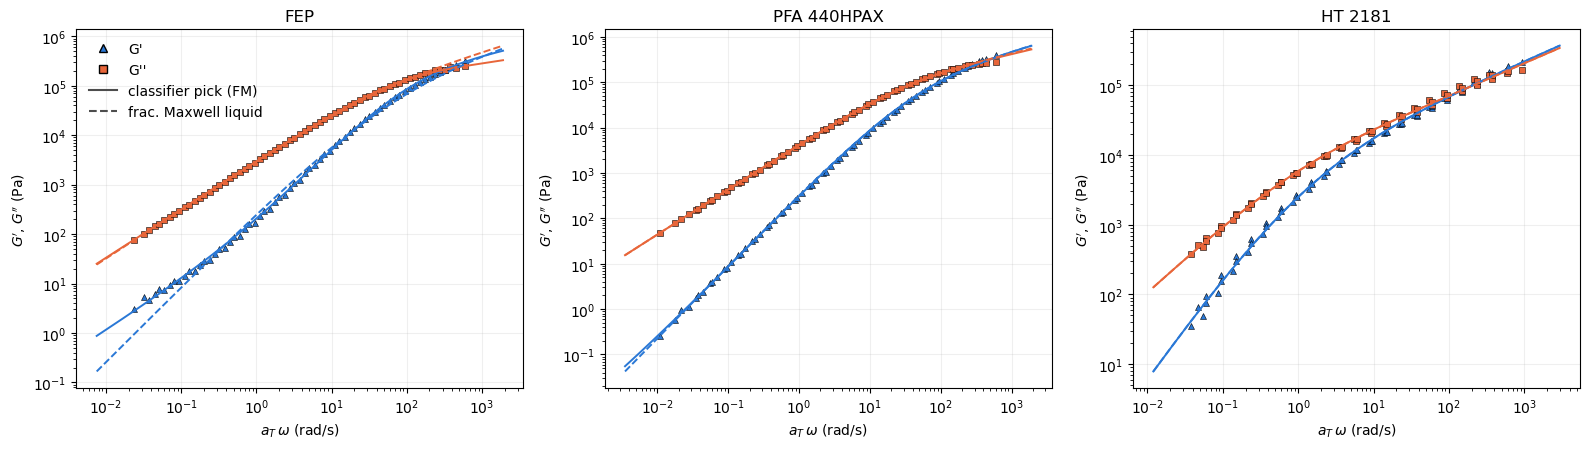

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, name in zip(axes, MASTER):
    m = MASTER[name]
    ww = np.logspace(np.log10(m["w"].min()) - 0.5, np.log10(m["w"].max()) + 0.5, 300)
    ax.plot(m["w"], m["G'"], "^", color="#2a78d6", mec="k", mew=0.4, ms=5, label="G' (GP-shifted)")
    ax.plot(m["w"], m["G''"], "s", color="#e8663a", mec="k", mew=0.4, ms=5, label="G'' (GP-shifted)")
    for key, ls in [("auto", "-"), ("FML", "--")]:
        g1, g2 = FITS[name][key].predict(ww)
        lab = FITS[name][key].model.replace("Fractional", "Frac. ")
        ax.plot(ww, g1, ls, color="#2a78d6", lw=1.4)
        ax.plot(ww, g2, ls, color="#e8663a", lw=1.4)
    ax.set_xscale("log"); ax.set_yscale("log"); pure_decades(ax); ax.grid(alpha=0.2)
    ax.set_title(name)
    ax.set_xlabel(r"$a_T\,\omega$ (rad/s)"); ax.set_ylabel(r"$G'$, $G''$ (Pa)")
handles = [Line2D([], [], color="#2a78d6", marker="^", mec="k", ls="none", label="G'"),
           Line2D([], [], color="#e8663a", marker="s", mec="k", ls="none", label="G''"),
           Line2D([], [], color="0.3", ls="-", label="classifier pick (FM)"),
           Line2D([], [], color="0.3", ls="--", label="frac. Maxwell liquid")]
axes[0].legend(handles=handles, frameon=False, loc="upper left")
fig.tight_layout()
save_fig(fig, "pyrheo_fractional_fits")
plt.show()

## What the HT activation energy does to the optimum

The line-speed optimum sits at 330 °C, past the last HT sweep at 315 °C, so it rests on the HT Arrhenius extrapolation.
Here the optimizer from `optimization/line_speed_optimization.ipynb` is rerun with each HT $E_a$ from the table above.
Only $E_a$ changes. The Cross parameters at $T_\text{ref} = 300$ °C and everything about FEP stay as in the report.

In [25]:
sys.path.insert(0, str(Path("..").resolve()))
from scipy.optimize import brentq, minimize_scalar
from wirecoating import WireCoatingDie, CrossLayer

R_W, R_D, L_LAND = 0.577e-3 / 2, 1.25e-3 / 2, 0.10e-3
TAU_C, T_FEP = 2e5, 0.20e-3
FEP = CrossLayer(eta0=3040, lam=0.0103, m=0.686, E_a=51.4e3, T_ref=330 + K0, name="FEP 9835", rho_melt=1400, rho_solid=2100)


def ht_layer(E_a_kJ):
    return CrossLayer(eta0=12780, lam=1.0345, m=0.529, E_a=E_a_kJ * 1e3, T_ref=300 + K0, name="HT 2181", rho_melt=1400, rho_solid=1700)


def speed_limit(layers, thicknesses, T):
    state = {"warm": None}

    def g(lnV):
        sol = WireCoatingDie(R_W, R_D, np.exp(lnV), list(layers), L=L_LAND).solve(
            thicknesses=thicknesses, T=T, warm_start=state["warm"])
        state["warm"] = sol
        return max(abs(sol.tau_wire), abs(sol.tau_die)) / TAU_C - 1
    return float(np.exp(brentq(g, np.log(1e-4), np.log(20.0), xtol=1e-10)))


def best_design(E_a_kJ, T_C):
    layers = (FEP, ht_layer(E_a_kJ))
    res = minimize_scalar(lambda x: -speed_limit(layers, [T_FEP, x * 1e-3], T_C + K0),
                          bounds=(0.002, 0.05), method="bounded", options={"xatol": 1e-5})
    return res.x, -res.fun


cases = {"report (Trios)": EA["HT 2181"]["Trios"][0]}
cases.update({f"GP {q}": EA["HT 2181"][q][0] for q in QUANTITIES})
rows = []
for label, Ea in cases.items():
    for T_C in (315, 330):
        t_ht, V = best_design(Ea, T_C)
        rows.append({"HT E_a source": label, "E_a [kJ/mol]": Ea, "T [°C]": T_C,
                     "t_HT* [mm]": t_ht, "V* [m/s]": V, "V* [m/min]": 60 * V})
SENS = pd.DataFrame(rows).set_index(["T [°C]", "HT E_a source"])
SENS.sort_index()

E_a [kJ/mol]  t_HT* [mm]  V* [m/s]  V* [m/min]
T [°C] HT E_a source                                                 
315    GP G'                  106.5     0.02826   0.03888       2.333
       GP G''                 87.57      0.0279   0.03559       2.135
       GP tan δ               139.8     0.02854   0.04555       2.733
       GP |G*|                90.28     0.02797   0.03604       2.162
       report (Trios)         92.44     0.02801    0.0364       2.184
330    GP G'                  106.5      0.0285   0.06485       3.891
       GP G''                 87.57     0.02845   0.05432       3.259
       GP tan δ               139.8     0.02738   0.08947       5.368
       GP |G*|                90.28     0.02849    0.0557       3.342
       report (Trios)         92.44     0.02851   0.05683        3.41

In [26]:
SENS.sort_index().to_latex(
    "tables/HT-sensitivity.tex",
    float_format=lambda x: f"{x:.3g}",
)

## Takeaways

**FEP and PFA superpose well, and the GP mostly agrees with Trios.** Shifting on $G''$ or $|G^*|$ reproduces the Trios $a_T$ to within
about 0.01 and gives $E_a$ within 1 kJ/mol of the report (FEP 49.8 ± 1.4, PFA 45.5 ± 1.4 kJ/mol on $|G^*|$). Shifting on $G'$ or $\tan\delta$ instead gives $a_T$ values that differ from these by
5–20%, well beyond the GP's ±1–5% uncertainty. At low frequency $G'$ is small and noisy (single-digit Pa for FEP), and $\tan\delta = G''/G'$ inherits that noise.
So for these two, $G''$ or $|G^*|$ is the more trustworthy thing to shift, and the GP uncertainty only covers the noise in each curve, not the choice of quantity.

**HT 2181 is ill-conditioned for horizontal shifting.** Above about 1 rad/s, both moduli follow near-parallel power laws with slopes of
0.5–0.6 and $G' \approx G''$, which looks like a gel. On a straight log-log line the overlap hardly changes as one isotherm slides along another, so the horizontal shift is
set by small curvature differences and by any small vertical offset between sweeps, which the fit can only absorb into $a_T$. That is why
Trios's $\tan\delta$ shift didn't collapse the viscosity data. Each quantity picks a different compromise, and the HT activation energy ranges from 88 kJ/mol ($G''$)
to 140 kJ/mol ($\tan\delta$). The "true" value can't be pinned down from three sweeps over 30 °C. The extra curvature in the HT low-frequency slopes, which differs between
temperatures, also suggests the material may not be thermorheologically simple.

**That spread changes the headline result.** With the Cross parameters held fixed, the 330 °C optimum ranges from 3.26 m/min ($E_a$ from $G''$)
to 5.37 m/min ($E_a$ from $\tan\delta$). The report's 3.41 m/min sits near the low end. At 315 °C, only 15 °C from the 300 °C reference, the
spread narrows to 2.14–2.73 m/min. The optimal HT thickness hardly moves (0.027–0.029 mm), so the *design* holds up even though the *speed* doesn't.
This supports quoting the 315 °C number as the conservative result, and it shows that a sweep of HT at 330 °C is the single most useful measurement to add.

**`pyRheo`'s classifier picks the fractional Maxwell model for all three polymers.** In every case the fit drives $\alpha$ to 0.98–1.0, so the
spring-pot it pairs with is really a dashpot (a fractional Maxwell liquid). For PFA and HT the 3-parameter FML fits as well as FM, and its
$\eta_s$ lands within 5% (PFA) and 12% (HT) of the Cross $\eta_0$. For FEP, FML is much worse (20% vs 6% rms error) because the low-frequency $G'$ has a slope near 1, not
the terminal slope of 2, so FEP has not reached its terminal regime in this window and $\alpha < 1$ matters. That fits with FEP needing a Cross
fit that leans on the plateau. The spring-pot order $\beta$ rises from 0.29 (FEP) to 0.39 (PFA) to 0.47 (HT), which ranks the materials the same way
as their shear thinning.

**Caveats.** The GP noise floor is the package default (4%). The $E_a$ uncertainties come from two shift factors per polymer, so they
are propagated, not checked against scatter. The V\* rerun changes only $E_a$; refitting the Cross model to each set of master curves would shift $\lambda$ a little too.
All shifts are horizontal only. `MasterCurve.change_ref` has a bug for states below the reference, so this notebook rebases the shift factors by hand.
